In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

In [5]:
df = pd.read_csv('../data/process/telco_customer_churn_cleaned.csv')

In [24]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [6]:
print("data Shape:", df.shape)

data Shape: (7043, 21)


In [7]:
df["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [8]:
churn_percentage = (
    df["Churn"].value_counts(normalize=True) * 100
)

print(churn_percentage)

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


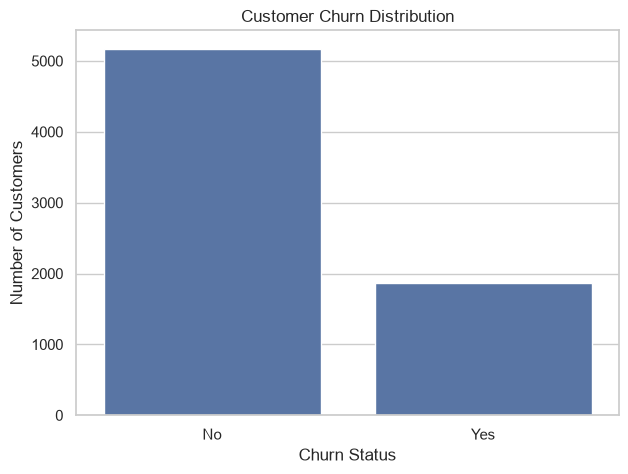

In [9]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Churn"
)

plt.title("Customer Churn Distribution")
plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")

plt.show()

Berdasarkan hasil analisis, sebanyak 1869 pelanggan atau sekitar 26.54% mengalami churn, sedangkan 5174 pelanggan atau 73.46% tetap berlangganan. Hal ini menunjukkan bahwa sebagian besar pelanggan masih bertahan, tetapi tingkat churn tetap perlu diperhatikan oleh perusahaan.

In [16]:
df.groupby(["Contract", "Churn"]).size()

Contract        Churn
Month-to-month  No       2220
                Yes      1655
One year        No       1307
                Yes       166
Two year        No       1647
                Yes        48
dtype: int64

In [17]:
contract_churn = df.groupby("Contract")["Churn"].apply(
    lambda x: (x == "Yes").mean() * 100
)

print(contract_churn)

Contract
Month-to-month    42.709677
One year          11.269518
Two year           2.831858
Name: Churn, dtype: float64


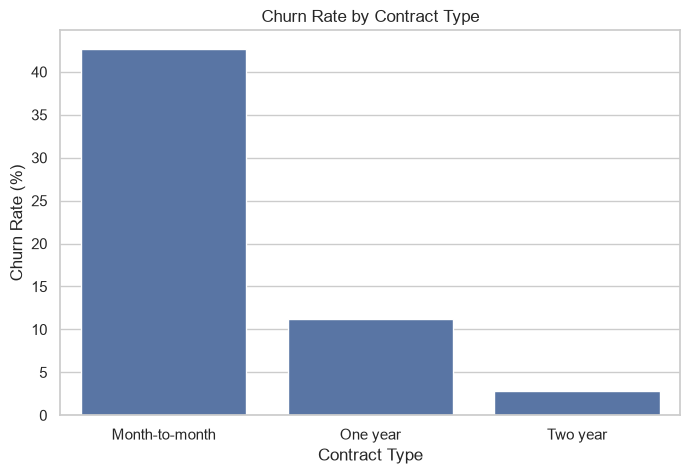

In [18]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=contract_churn.index,
    y=contract_churn.values
)

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")

plt.show()

Pelanggan dengan kontrak Month-to-month memiliki churn rate paling tinggi dibandingkan jenis kontrak lainnya. Hal ini menunjukkan bahwa pelanggan dengan komitmen berlangganan jangka pendek cenderung lebih mudah meninggalkan layanan.

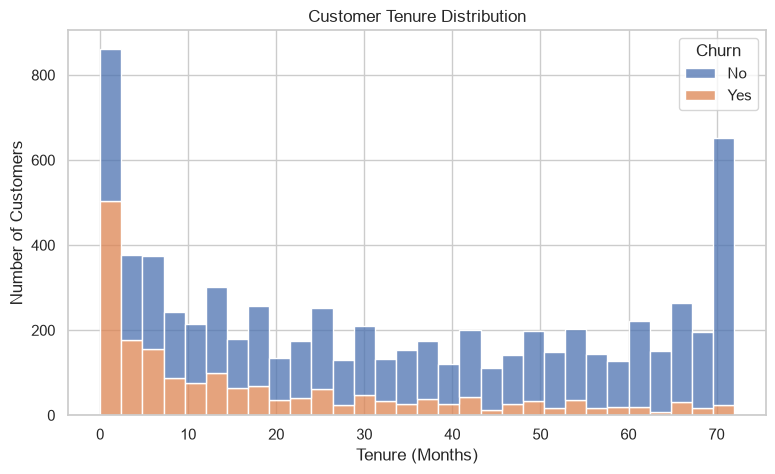

In [12]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="tenure",
    hue="Churn",
    bins=30,
    multiple="stack"
)

plt.title("Customer Tenure Distribution")
plt.xlabel("Tenure (Months)")
plt.ylabel("Number of Customers")

plt.show()

In [15]:
tenure_analysis = df.groupby("Churn")["tenure"].mean()

print(tenure_analysis)

Churn
No     37.569965
Yes    17.979133
Name: tenure, dtype: float64


Pelanggan yang mengalami churn memiliki rata-rata tenure lebih rendah dibandingkan pelanggan yang masih bertahan. Hal ini mengindikasikan bahwa pelanggan baru mungkin lebih rentan meninggalkan layanan.

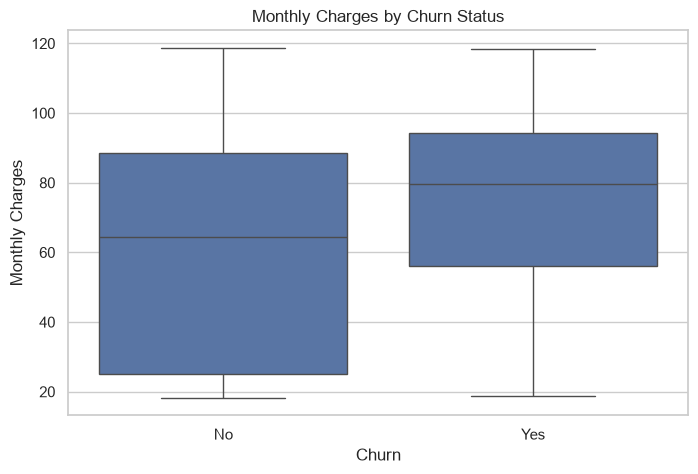

In [13]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges"
)

plt.title("Monthly Charges by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")

plt.show()

In [23]:
monthly_charges_analysis = df.groupby("Churn")["MonthlyCharges"].mean()

print(monthly_charges_analysis)

Churn
No     61.265124
Yes    74.441332
Name: MonthlyCharges, dtype: float64


Terdapat perbedaan distribusi MonthlyCharges antara pelanggan yang churn dan tidak churn. Hal ini dapat menjadi indikasi bahwa biaya layanan berkaitan dengan keputusan pelanggan untuk berhenti berlangganan.

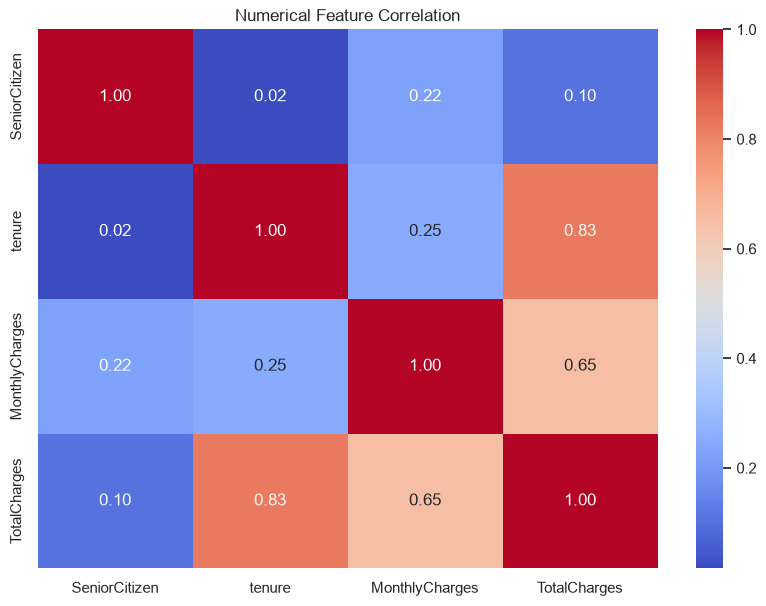

In [22]:
numeric_df = df.select_dtypes(include=["int64", "float64"])

correlation = numeric_df.corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Numerical Feature Correlation")

plt.show()